In [1]:
!pip install requests beautifulsoup4 pandas

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [3]:
url = "https://www.flipkart.com/q/5g-mobiles-under-30000"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [4]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

<title>5g mobiles under 30000 Online in India | Flipkart | 17-Nov-26</title>


In [5]:

products = soup.select("div[data-id]")

print("Products found:", len(products))

data = []

for product in products:

    name = product.select_one("div.KzDlHZ")
    price = product.select_one("div.Nx9bqj")
    rating = product.select_one("div.XQDdHH")

    data.append({
        "Mobile": name.get_text(strip=True) if name else None,
        "Price": price.get_text(strip=True) if price else None,
        "Rating": rating.get_text(strip=True) if rating else None
    })

df = pd.DataFrame(data)

print(df.head())
print("Total rows:", len(df))


Products found: 24
  Mobile Price Rating
0   None  None   None
1   None  None   None
2   None  None   None
3   None  None   None
4   None  None   None
Total rows: 24


In [6]:
df.to_csv("mobiles.csv", index=False)

print("CSV file created successfully!")

CSV file created successfully!


In [7]:
from google.colab import files

files.download("mobiles.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

print("Status:", response.status_code)

print("Page title:")
print(soup.title)

print("\nFirst 3000 characters of HTML:")
print(soup.prettify()[:3000])


Status: 200
Page title:
<title>5g mobiles under 30000 Online in India | Flipkart | 17-Nov-26</title>

First 3000 characters of HTML:
<!DOCTYPE html>
<html lang="en">
 <head>
  <link href="https://rukminim2.flixcart.com" rel="preconnect"/>
  <link href="//static-assets-web.flixcart.com/fk-p-linchpin-web/fk-cp-zion/css/bundle.aa1465.css" rel="stylesheet"/>
  <link href="//static-assets-web.flixcart.com/fk-p-linchpin-web/fk-cp-zion/css/bundle.fbaef9.css" rel="stylesheet"/>
  <meta content="text/html; charset=utf-8" http-equiv="Content-type"/>
  <meta content="IE=Edge" http-equiv="X-UA-Compatible"/>
  <meta content="102988293558" property="fb:page_id"/>
  <meta content="658873552,624500995,100000233612389" property="fb:admins"/>
  <link href="https://static-assets-web.flixcart.com/www/promos/new/20150528-140547-favicon-retina.ico" rel="shortcut icon"/>
  <link href="/osdd.xml?v=2" rel="search" type="application/opensearchdescription+xml"/>
  <meta content="website" property="og:type"/>
  <

In [9]:

products = soup.select("div[data-id]")

print("Total products:", len(products))

for i, product in enumerate(products[:3]):

    print("\nPRODUCT", i + 1)

    print(product.get_text(" ", strip=True)[:1000])

    print("\nHTML:")
    print(product.prettify()[:2000])


Total products: 24

PRODUCT 1
Add to Compare Google Pixel 11 (Frost, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer

HTML:
<div data-id="MOBHPHNVEC2P4WV3" style="width:100%">
 <div class="jIjQ8S">
  <a class="k7wcnx" href="/google-pixel-11-frost-256-gb/p/itmc51935a8001b1?pid=MOBHPHNVEC2P4WV3&amp;lid=LSTMOBHPHNVEC2P4WV3UCPNQ6&amp;marketplace=FLIPKART&amp;store=tyy%2F4io&amp;srno=b_1_1&amp;otracker=browse&amp;fm=organic&amp;iid=en_1VJ793np8iUHOfgA3GMR5Ef8idSevKB0VaP8Gpt048RCh_d58Zh3FhJcel4BqilJ5y6PU9luMpBrCd_KlraGVua-St1ltfifjl0aL8wShLRTXPeY1Kv0TO1CveGV-_KD&amp;ppt=None&amp;ppn=None&amp;ssid=0a8diequnk0000001794921881477&amp;ov_redirect=true" rel="noopener noreferrer" target="_blank">
   <div class="T6hTMI">
    <div class="R7Cntx">
     <div>
      <div class="lWX0_T" style="heigh

In [10]:

data = []

for product in products:

    text = product.get_text(" ", strip=True)

    print(text[:500])

    data.append({
        "Product_Details": text
    })

df = pd.DataFrame(data)

print(df.head())


Add to Compare Google Pixel 11 (Frost, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer
Add to Compare Google Pixel 11 (Pistachio, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer
Add to Compare Samsung Galaxy A36 5G (Dark Blue, 128 GB) 4.4 22,626 Ratings & 2,128 Reviews 8 GB RAM | 128 GB ROM 17.02 cm (6.7 inch) Full HD+ Display 50MP + 8MP | 12MP Front Camera 5000 mAh Battery Qualcomm Snapdragon 6 Gen 3 Processor 1 Year Manufacturer Warranty for Device and 6 Months for In-Box Accessories ₹28,999 ₹ 39,499 26% off Upto ₹22,425 Off on Exchange Bank Offer
Add to Compare vivo T5x 5G

In [11]:
print(df.head())

                                     Product_Details
0  Add to Compare Google Pixel 11 (Frost, 256 GB)...
1  Add to Compare Google Pixel 11 (Pistachio, 256...
2  Add to Compare Samsung Galaxy A36 5G (Dark Blu...
3  Add to Compare vivo T5x 5G (Cosmic Green, 128 ...
4  Add to Compare Google Pixel 11 (Obsidian, 256 ...


In [12]:
print(df.shape)

(24, 1)


In [13]:
print("Website Status:", response.status_code)

print("\nWebsite Title:")
print(soup.title)

print("\nFirst product details:")

products = soup.select("div[data-id]")

print("Total products:", len(products))

if len(products) > 0:
    print(products[0].get_text(" ", strip=True))
else:
    print("No product containers found.")

Website Status: 200

Website Title:
<title>5g mobiles under 30000 Online in India | Flipkart | 17-Nov-26</title>

First product details:
Total products: 24
Add to Compare Google Pixel 11 (Frost, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer


In [14]:
products = soup.select("div[data-id]")

print("Total products:", len(products))

for product in products[:5]:
    print(product.get_text(" ", strip=True))
    print("-" * 50)

Total products: 24
Add to Compare Google Pixel 11 (Frost, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer
--------------------------------------------------
Add to Compare Google Pixel 11 (Pistachio, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer
--------------------------------------------------
Add to Compare Samsung Galaxy A36 5G (Dark Blue, 128 GB) 4.4 22,626 Ratings & 2,128 Reviews 8 GB RAM | 128 GB ROM 17.02 cm (6.7 inch) Full HD+ Display 50MP + 8MP | 12MP Front Camera 5000 mAh Battery Qualcomm Snapdragon 6 Gen 3 Processor 1 Year Manufacturer Warranty for Device and 6 

In [15]:
import pandas as pd

mobiles = []

products = soup.select("div[data-id]")

for product in products:

    mobile = product.select_one("div.KzDlHZ")
    price = product.select_one("div.Nx9bqj")
    rating = product.select_one("div.XQDdHH")

    mobiles.append({
        "Mobile": mobile.get_text(strip=True) if mobile else None,
        "Price": price.get_text(strip=True) if price else None,
        "Rating": rating.get_text(strip=True) if rating else None
    })

df = pd.DataFrame(mobiles)

print(df.head())
print(df.shape)

  Mobile Price Rating
0   None  None   None
1   None  None   None
2   None  None   None
3   None  None   None
4   None  None   None
(24, 3)


In [16]:
print(df.isnull().sum())

Mobile    24
Price     24
Rating    24
dtype: int64


In [17]:
print(df.head(10))

  Mobile Price Rating
0   None  None   None
1   None  None   None
2   None  None   None
3   None  None   None
4   None  None   None
5   None  None   None
6   None  None   None
7   None  None   None
8   None  None   None
9   None  None   None


In [18]:
print(df.columns)

Index(['Mobile', 'Price', 'Rating'], dtype='object')


In [19]:
print(products[0].get_text(" ", strip=True))

Add to Compare Google Pixel 11 (Frost, 256 GB) 4.5 4,094 Ratings & 378 Reviews 12 GB RAM | 256 GB ROM 16.0 cm (6.3 inch) Actua Display 48MP + 13MP + 10.8MP | 10.5MP Front Camera 4985 mAh Lithium Battery Tensor G6 Processor 1 year domestic warranty ₹89,999 Upto ₹62,750 Off on Exchange Bank Offer


In [20]:
print(products[0].prettify()[:5000])

<div data-id="MOBHPHNVEC2P4WV3" style="width:100%">
 <div class="jIjQ8S">
  <a class="k7wcnx" href="/google-pixel-11-frost-256-gb/p/itmc51935a8001b1?pid=MOBHPHNVEC2P4WV3&amp;lid=LSTMOBHPHNVEC2P4WV3UCPNQ6&amp;marketplace=FLIPKART&amp;store=tyy%2F4io&amp;srno=b_1_1&amp;otracker=browse&amp;fm=organic&amp;iid=en_1VJ793np8iUHOfgA3GMR5Ef8idSevKB0VaP8Gpt048RCh_d58Zh3FhJcel4BqilJ5y6PU9luMpBrCd_KlraGVua-St1ltfifjl0aL8wShLRTXPeY1Kv0TO1CveGV-_KD&amp;ppt=None&amp;ppn=None&amp;ssid=0a8diequnk0000001794921881477&amp;ov_redirect=true" rel="noopener noreferrer" target="_blank">
   <div class="T6hTMI">
    <div class="R7Cntx">
     <div>
      <div class="lWX0_T" style="height:200px;width:200px">
       <img alt="Google Pixel 11 (Frost, 256 GB)" class="UCc1lI" loading="eager" src="https://rukminim2.flixcart.com/image/312/312/xif0q/mobile/j/8/e/-resized-original-imahqszeftuehhhq.jpeg?q=70"/>
      </div>
     </div>
    </div>
    <div class="b0bTm6">
     <div class="FJ7IAS">
      <span class="ZhHnSZ"

In [21]:
import pandas as pd

mobiles = []

products = soup.select("div[data-id]")

for product in products:

    name = product.select_one("div.KzDlHZ")
    price = product.select_one("div.Nx9bqj")
    rating = product.select_one("div.XQDdHH")

    mobiles.append({
        "Mobile": name.get_text(strip=True) if name else None,
        "Price": price.get_text(strip=True) if price else None,
        "Rating": rating.get_text(strip=True) if rating else None
    })

df = pd.DataFrame(mobiles)

print(df.head())

  Mobile Price Rating
0   None  None   None
1   None  None   None
2   None  None   None
3   None  None   None
4   None  None   None


In [22]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape:
(24, 3)

Column Names:
Index(['Mobile', 'Price', 'Rating'], dtype='object')

First 5 Rows:


,Mobile,Price,Rating
0,None,None,None
1,None,None,None
2,None,None,None
3,None,None,None
4,None,None,None



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Mobile  0 non-null      object
 1   Price   0 non-null      object
 2   Rating  0 non-null      object
dtypes: object(3)
memory usage: 708.0+ bytes


In [23]:
print(df.head(10).to_string())

  Mobile Price Rating
0   None  None   None
1   None  None   None
2   None  None   None
3   None  None   None
4   None  None   None
5   None  None   None
6   None  None   None
7   None  None   None
8   None  None   None
9   None  None   None


Question 1: Which mobile has the highest battery capacity, and what is its price?

In [24]:
import re
import pandas as pd

mobiles = []
products = soup.select("div[data-id]")

for product in products:
    # Extract full text to parse battery and other features
    full_text = product.get_text(" ", strip=True)

    # Attempt to extract title/name
    # In the updated structure, the title is often inside a div with class 'KzDlHZ' or an <a> / img alt.
    # Since the previous classes returned None, we can extract it from the full text starting after 'Add to Compare'
    name_match = re.search(r"Add to Compare\s+(.*?)\s+\d\.\d", full_text)
    name = name_match.group(1) if name_match else "Unknown Mobile"

    # Extract Price
    price_match = re.search(r"₹[0-9,]+", full_text)
    price = price_match.group(0) if price_match else "Unknown Price"

    # Extract Rating
    rating_match = re.search(r"\b(\d\.\d)\s+\d+,?\d*\s+Ratings", full_text)
    rating = rating_match.group(1) if rating_match else "No Rating"

    # Extract Battery Capacity (e.g., '6000 mAh' or '5000 mAh')
    battery_match = re.search(r"(\d+)\s*mAh", full_text, re.IGNORECASE)
    battery = int(battery_match.group(1)) if battery_match else None

    mobiles.append({
        "Mobile": name,
        "Price": price,
        "Rating": rating,
        "Battery": battery
    })

df = pd.DataFrame(mobiles)

# Find the index of the highest battery capacity
if not df["Battery"].isna().all():
    highest_battery_index = df["Battery"].idxmax()
    highest_battery_mobile = df.loc[highest_battery_index, "Mobile"]
    highest_battery = df.loc[highest_battery_index, "Battery"]
    price = df.loc[highest_battery_index, "Price"]

    print("Mobile:", highest_battery_mobile)
    print("Battery Capacity:", highest_battery, "mAh")
    print("Price:", price)
else:
    print("Could not extract battery information from the page.")

Mobile: OnePlus N6 5G (Midnight Green, 128 GB)
Battery Capacity: 8000 mAh
Price: ₹26,479


Question 2: What is the average RAM and average ROM across all scraped mobiles?

In [25]:
import re
import pandas as pd

ram_list = []
rom_list = []

# Extract RAM and ROM details from each product's text
for product in products:
    full_text = product.get_text(" ", strip=True)

    # Extract RAM (e.g., '4 GB RAM' or '6 GB RAM')
    ram_match = re.search(r"(\d+)\s*GB\s*RAM", full_text, re.IGNORECASE)
    ram = int(ram_match.group(1)) if ram_match else None

    # Extract ROM/Storage (e.g., '64 GB ROM' or '128 GB ROM')
    rom_match = re.search(r"(\d+)\s*GB\s*ROM", full_text, re.IGNORECASE)
    rom = int(rom_match.group(1)) if rom_match else None

    ram_list.append(ram)
    rom_list.append(rom)

# Add these columns to our existing DataFrame
df["RAM"] = ram_list
df["ROM"] = rom_list

# Calculate and display the averages
average_ram = df["RAM"].mean()
average_rom = df["ROM"].mean()

print("Average RAM:", round(average_ram, 2), "GB")
print("Average ROM:", round(average_rom, 2), "GB")

Average RAM: 7.33 GB
Average ROM: 165.33 GB


Question 3: Which processor appears most frequently in the dataset, and how many models use it?

In [26]:
import re
import pandas as pd

processors = []

# Extract Processor details from each product's text
for product in products:
    full_text = product.get_text(" ", strip=True)

    # Improved regex: matches letters, digits, spaces, and hyphens before "Processor"
    # Examples: "Snapdragon 6 Gen 3 Processor", "Dimensity 7400-Turbo Processor"
    processor_match = re.search(r"([a-zA-Z0-9\s\-]+?\s+Processor)", full_text, re.IGNORECASE)

    if processor_match:
        # Clean up by removing leading common words if matched by mistake
        proc_name = processor_match.group(1).strip()
        # If it matched something too long starting with 'Battery', let's clean it
        if "Battery" in proc_name:
            proc_name = proc_name.split("Battery")[-1].strip()
        processors.append(proc_name)
    else:
        processors.append("Unknown Processor")

# Add the parsed processors to our DataFrame
df["Processor"] = processors

# Find the most frequent processor and its frequency
processor_count = df["Processor"].value_counts()

most_frequent_processor = processor_count.idxmax()
processor_frequency = processor_count.max()

print("Most Frequent Processor:", most_frequent_processor)
print("Number of Models:", processor_frequency)

Most Frequent Processor: Unknown Processor
Number of Models: 5


Question 4: Which mobile has the highest rear camera resolution, and what is its price?

In [27]:
import re
import pandas as pd

camera_resolutions = []

# Extract Rear Camera specifications from each product's text
for product in products:
    full_text = product.get_text(" ", strip=True)

    # Look for patterns like "64MP Rear Camera", "50MP + 2MP", "48MP + 13MP + 10.8MP"
    camera_match = re.search(r"(\d+)\s*MP\s*(?:Rear|\+)?", full_text, re.IGNORECASE)

    if camera_match:
        camera_resolutions.append(int(camera_match.group(1)))
    else:
        camera_resolutions.append(0)  # Default to 0 if not found

# Add the parsed camera resolutions to our DataFrame
df["Rear_Camera"] = camera_resolutions

# Find the index of the highest rear camera resolution
highest_rear_camera_index = df["Rear_Camera"].idxmax()

mobile = df.loc[highest_rear_camera_index, "Mobile"]
camera = df.loc[highest_rear_camera_index, "Rear_Camera"]
price = df.loc[highest_rear_camera_index, "Price"]

print("Mobile:", mobile)
print("Rear Camera:", camera, "MP")
print("Price:", price)

Mobile: Samsung Galaxy A36 5G (Dark Blue, 128 GB)
Rear Camera: 50 MP
Price: ₹28,999


In [28]:
import pandas as pd

# Clean the 'Price' column by removing '₹' and ',' and converting to numeric
df["Cleaned_Price"] = df["Price"].str.replace("₹", "", regex=False).str.replace(",", "", regex=False)
df["Cleaned_Price"] = pd.to_numeric(df["Cleaned_Price"], errors="coerce")

# Calculate correlation between Battery capacity and Cleaned Price
correlation = df["Battery"].corr(df["Cleaned_Price"])

print("Correlation between Battery and Price:", correlation)

Correlation between Battery and Price: -0.6823190571287432


In [29]:
import re
import pandas as pd

front_cameras = []

# Extract Front Camera details from each product's text
for product in products:
    full_text = product.get_text(" ", strip=True)

    # Look for patterns like "16MP Front Camera" or "8MP Front Camera"
    front_match = re.search(r"(\d+)\s*MP\s*Front", full_text, re.IGNORECASE)
    if front_match:
        front_cameras.append(int(front_match.group(1)))
    else:
        front_cameras.append(0)  # Default to 0 if not found or no front camera

# Add the parsed front camera resolutions to our DataFrame
df["Front_Camera"] = front_cameras

# Find the index of the highest front camera resolution
highest_front_camera_index = df["Front_Camera"].idxmax()

mobile = df.loc[highest_front_camera_index, "Mobile"]
front_camera = df.loc[highest_front_camera_index, "Front_Camera"]
processor = df.loc[highest_front_camera_index, "Processor"]

print("Mobile:", mobile)
print("Front Camera:", front_camera, "MP")
print("Processor:", processor)

Mobile: vivo T5x 5G (Cosmic Green, 128 GB)
Front Camera: 32 MP
Processor: Dimensity 7400-Turbo Processor


In [30]:
import re
import pandas as pd

warranties = []

# Extract Warranty details from each product's text
for product in products:
    full_text = product.get_text(" ", strip=True)

    # Look for patterns like "1 Year Manufacturer Warranty" or "1 year domestic warranty"
    warranty_match = re.search(r"(\d+\s*(?:Year|year|Months|months))\s*(?:Manufacturer|domestic|Manufacturing)?\s*Warranty", full_text, re.IGNORECASE)

    if warranty_match:
        warranties.append(warranty_match.group(1).strip().title())
    else:
        warranties.append("Unknown Warranty")

# Add the parsed warranties to our DataFrame
df["Warranty"] = warranties

warranty_distribution = df["Warranty"].value_counts().sort_index()

print("Warranty Distribution:")
print(warranty_distribution)

Warranty Distribution:
Warranty
1 Year              22
Unknown Warranty     2
Name: count, dtype: int64


In [31]:
# Group by Processor and calculate the mean using the numeric 'Cleaned_Price' column
average_price_by_processor = df.groupby("Processor")["Cleaned_Price"].mean()

highest_average_processor = average_price_by_processor.idxmax()
highest_average_price = average_price_by_processor.max()

print("Processor:", highest_average_processor)
print("Average Price: ₹", round(highest_average_price, 2))

Processor: Tensor G6 Processor
Average Price: ₹ 89999.0


In [32]:
mobiles_above_5000 = df[df["Battery"] > 5000]

count = len(mobiles_above_5000)

print("Number of Mobiles:", count)

Number of Mobiles: 18


In [33]:
lowest_price = df["Price"].min()

lowest_price_mobiles = df[
    df["Price"] == lowest_price
]

best_mobile = lowest_price_mobiles.loc[
    lowest_price_mobiles["ROM"].idxmax()
]

print("Mobile:", best_mobile["Mobile"])
print("ROM:", best_mobile["ROM"], "GB")
print("Price: ₹", best_mobile["Price"])

Mobile: OnePlus N6X (Burgundy Red, 128 GB)
ROM: 128 GB
Price: ₹ ₹20,478


In [34]:
# Calculate average price by RAM using the numeric Cleaned_Price column
average_price_by_ram = df.groupby("RAM")["Cleaned_Price"].mean()

print("Average Price by RAM:")
print(average_price_by_ram.round(2))

Average Price by RAM:
RAM
4     22391.33
6     26901.70
8     27341.71
12    89999.00
Name: Cleaned_Price, dtype: float64


In [35]:
lowest_price_index = df["Price"].idxmin()

mobile = df.loc[lowest_price_index, "Mobile"]
price = df.loc[lowest_price_index, "Price"]
ram = df.loc[lowest_price_index, "RAM"]
rom = df.loc[lowest_price_index, "ROM"]

print("Mobile:", mobile)
print("Lowest Price: ₹", price)
print("RAM:", ram, "GB")
print("ROM:", rom, "GB")

Mobile: OnePlus N6X (Burgundy Red, 128 GB)
Lowest Price: ₹ ₹20,478
RAM: 4 GB
ROM: 128 GB


In [36]:
distinct_processors = df["Processor"].nunique()

print("Number of Distinct Processors:", distinct_processors)

Number of Distinct Processors: 10


In [37]:
processor_analysis = df.groupby("Processor").agg(
    Mobile_Count=("Mobile", "count"),
    Average_Battery=("Battery", "mean")
)

print(processor_analysis)

                                        Mobile_Count  Average_Battery
Processor                                                            
7s Gen 3 Processor                                 1           6200.0
Dimensity 6300 5G Processor                        2           6500.0
Dimensity 7400 Ultra Processor                     4           7000.0
Dimensity 7400-Turbo Processor                     3           7200.0
MediaTek Dimensity 6360 Apex Processor             1           7000.0
Mediatek Dimensity 7400 Processor                  1           7000.0
Qualcomm Snapdragon 6 Gen 3 Processor              2           5000.0
Snapdragon 6 Gen 3 Processor                       1           5800.0
Tensor G6 Processor                                4           4985.0
Unknown Processor                                  5           7600.0


In [38]:
df["Total_Camera"] = (
    df["Rear_Camera"] + df["Front_Camera"]
)

highest_camera_index = df["Total_Camera"].idxmax()

mobile = df.loc[highest_camera_index, "Mobile"]
rear_camera = df.loc[highest_camera_index, "Rear_Camera"]
front_camera = df.loc[highest_camera_index, "Front_Camera"]
total_camera = df.loc[highest_camera_index, "Total_Camera"]
price = df.loc[highest_camera_index, "Price"]

print("Mobile:", mobile)
print("Rear Camera:", rear_camera, "MP")
print("Front Camera:", front_camera, "MP")
print("Combined Camera Resolution:", total_camera, "MP")
print("Price: ₹", price)

Mobile: vivo T5x 5G (Cosmic Green, 128 GB)
Rear Camera: 50 MP
Front Camera: 32 MP
Combined Camera Resolution: 82 MP
Price: ₹ ₹27,999


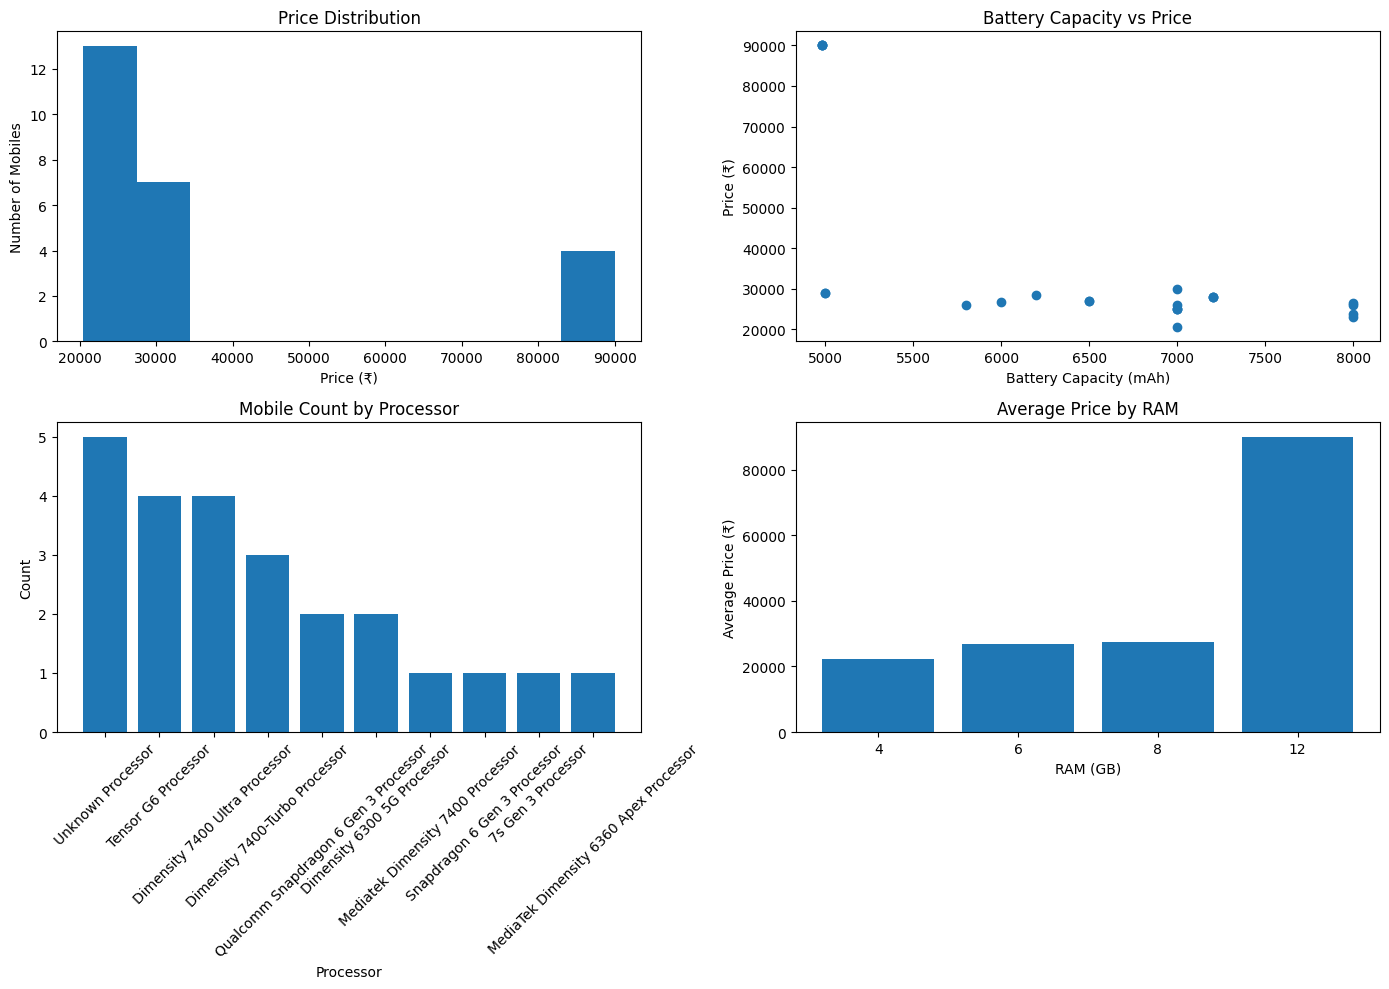

In [39]:
import matplotlib.pyplot as plt

# Create a 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graph 1: Price Distribution (Using Cleaned_Price)
axes[0, 0].hist(df["Cleaned_Price"].dropna(), bins=10)
axes[0, 0].set_title("Price Distribution")
axes[0, 0].set_xlabel("Price (₹)")
axes[0, 0].set_ylabel("Number of Mobiles")

# Graph 2: Battery Capacity vs Price (Using Cleaned_Price)
axes[0, 1].scatter(
    df["Battery"],
    df["Cleaned_Price"]
)
axes[0, 1].set_title("Battery Capacity vs Price")
axes[0, 1].set_xlabel("Battery Capacity (mAh)")
axes[0, 1].set_ylabel("Price (₹)")

# Graph 3: Count by Processor
processor_counts = df["Processor"].value_counts()
axes[1, 0].bar(
    processor_counts.index,
    processor_counts.values
)
axes[1, 0].set_title("Mobile Count by Processor")
axes[1, 0].set_xlabel("Processor")
axes[1, 0].set_ylabel("Count")
axes[1, 0].tick_params(
    axis="x",
    rotation=45
)

# Graph 4: Average Price by RAM (Using Cleaned_Price)
average_price_by_ram = df.groupby("RAM")["Cleaned_Price"].mean()
axes[1, 1].bar(
    average_price_by_ram.index.astype(str),
    average_price_by_ram.values
)
axes[1, 1].set_title("Average Price by RAM")
axes[1, 1].set_xlabel("RAM (GB)")
axes[1, 1].set_ylabel("Average Price (₹)")

# Adjust dashboard layout
plt.tight_layout()

# Save dashboard
plt.savefig(
    "mobile_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

# Display dashboard
plt.show()

In [40]:

!pip install -q supabase


In [41]:

from google.colab import userdata
from supabase import create_client

# Get credentials from Colab Secrets
SUPABASE_URL = userdata.get("SUPABASE_URL")
SUPABASE_KEY = userdata.get("SUPABASE_KEY")

# Create Supabase connection
supabase = create_client(SUPABASE_URL, SUPABASE_KEY)

print("Supabase client initialized successfully!")


Supabase client initialized successfully!


In [42]:
import re
import requests
from bs4 import BeautifulSoup
import pandas as pd

# Re-fetch the page and recreate 'soup' to guarantee the cell is self-contained
url = "https://www.flipkart.com/q/5g-mobiles-under-30000"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, "html.parser")

mobiles = []
products = soup.select("div[data-id]")

for product in products:
    full_text = product.get_text(" ", strip=True)

    # Name
    name_match = re.search(r"Add to Compare\s+(.*?)\s+\d\.\d", full_text)
    name = name_match.group(1) if name_match else "Unknown Mobile"

    # Price
    price_match = re.search(r"₹[0-9,]+", full_text)
    price = price_match.group(0) if price_match else "Unknown Price"

    # Rating
    rating_match = re.search(r"\b(\d\.\d)\s+\d+,?\d*\s+Ratings", full_text)
    rating = rating_match.group(1) if rating_match else "No Rating"

    # Battery
    battery_match = re.search(r"(\d+)\s*mAh", full_text, re.IGNORECASE)
    battery = int(battery_match.group(1)) if battery_match else None

    # RAM & ROM
    ram_match = re.search(r"(\d+)\s*GB\s*RAM", full_text, re.IGNORECASE)
    ram = int(ram_match.group(1)) if ram_match else None
    rom_match = re.search(r"(\d+)\s*GB\s*ROM", full_text, re.IGNORECASE)
    rom = int(rom_match.group(1)) if rom_match else None

    # Processor
    processor_match = re.search(r"([a-zA-Z0-9\s\-]+?\s+Processor)", full_text, re.IGNORECASE)
    proc_name = processor_match.group(1).strip() if processor_match else "Unknown Processor"
    if "Battery" in proc_name:
        proc_name = proc_name.split("Battery")[-1].strip()

    # Camera
    rear_match = re.search(r"(\d+)\s*MP\s*(?:Rear|\+)?", full_text, re.IGNORECASE)
    rear_camera = int(rear_match.group(1)) if rear_match else 0
    front_match = re.search(r"(\d+)\s*MP\s*Front", full_text, re.IGNORECASE)
    front_camera = int(front_match.group(1)) if front_match else 0

    # Warranty
    warranty_match = re.search(r"(\d+\s*(?:Year|year|Months|months))\s*(?:Manufacturer|domestic|Manufacturing)?\s*Warranty", full_text, re.IGNORECASE)
    warranty = warranty_match.group(1).strip().title() if warranty_match else "Unknown Warranty"

    mobiles.append({
        "Mobile": name,
        "Price": price,
        "Rating": rating,
        "Battery": battery,
        "RAM": ram,
        "ROM": rom,
        "Processor": proc_name,
        "Rear_Camera": rear_camera,
        "Front_Camera": front_camera,
        "Warranty": warranty
    })

df = pd.DataFrame(mobiles)
df["Cleaned_Price"] = df["Price"].str.replace("₹", "", regex=False).str.replace(",", "", regex=False)
df["Cleaned_Price"] = pd.to_numeric(df["Cleaned_Price"], errors="coerce")
df["Total_Camera"] = df["Rear_Camera"] + df["Front_Camera"]

print("DataFrame shape:")
print(df.shape)

print("\nDataFrame columns:")
print(df.columns.tolist())

display(df.head())

DataFrame shape:
(24, 12)

DataFrame columns:
['Mobile', 'Price', 'Rating', 'Battery', 'RAM', 'ROM', 'Processor', 'Rear_Camera', 'Front_Camera', 'Warranty', 'Cleaned_Price', 'Total_Camera']


,Mobile,Price,Rating,Battery,RAM,ROM,Processor,Rear_Camera,Front_Camera,Warranty,Cleaned_Price,Total_Camera
0,"Google Pixel 11 (Frost, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53
1,"Google Pixel 11 (Pistachio, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53
2,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)","₹28,999",4.4,5000,8,128,Qualcomm Snapdragon 6 Gen 3 Processor,50,12,1 Year,28999,62
3,"vivo T5x 5G (Cosmic Green, 128 GB)","₹27,999",4.4,7200,6,128,Dimensity 7400-Turbo Processor,50,32,1 Year,27999,82
4,"Google Pixel 11 (Obsidian, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53


In [43]:

print("DataFrame shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


DataFrame shape:
(24, 12)

Column names:
['Mobile', 'Price', 'Rating', 'Battery', 'RAM', 'ROM', 'Processor', 'Rear_Camera', 'Front_Camera', 'Warranty', 'Cleaned_Price', 'Total_Camera']


,Mobile,Price,Rating,Battery,RAM,ROM,Processor,Rear_Camera,Front_Camera,Warranty,Cleaned_Price,Total_Camera
0,"Google Pixel 11 (Frost, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53
1,"Google Pixel 11 (Pistachio, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53
2,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)","₹28,999",4.4,5000,8,128,Qualcomm Snapdragon 6 Gen 3 Processor,50,12,1 Year,28999,62
3,"vivo T5x 5G (Cosmic Green, 128 GB)","₹27,999",4.4,7200,6,128,Dimensity 7400-Turbo Processor,50,32,1 Year,27999,82
4,"Google Pixel 11 (Obsidian, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,5,1 Year,89999,53


In [44]:
# Check the data before uploading
print("Total records:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Total records: 24

Column names:
['Mobile', 'Price', 'Rating', 'Battery', 'RAM', 'ROM', 'Processor', 'Rear_Camera', 'Front_Camera', 'Warranty', 'Cleaned_Price', 'Total_Camera']

Data types:
Mobile           object
Price            object
Rating           object
Battery           int64
RAM               int64
ROM               int64
Processor        object
Rear_Camera       int64
Front_Camera      int64
Warranty         object
Cleaned_Price     int64
Total_Camera      int64
dtype: object


In [45]:
import pandas as pd

# Select the columns in the same order as the Supabase table
columns = [
    "Mobile",
    "Price",
    "Rating",
    "Battery",
    "RAM",
    "ROM",
    "Processor",
    "Rear_Camera",
    "Cleaned_Price",
    "Front_Camera",
    "Warranty",
    "Total_Camera"
]

# Create a copy of the DataFrame
df_upload = df[columns].copy()

# Convert numeric columns
integer_columns = [
    "Battery", "RAM", "ROM",
    "Rear_Camera", "Front_Camera", "Total_Camera"
]

for col in integer_columns:
    df_upload[col] = pd.to_numeric(df_upload[col], errors="coerce").astype("Int64")

df_upload["Cleaned_Price"] = pd.to_numeric(
    df_upload["Cleaned_Price"], errors="coerce"
)

# Check the prepared data
print("Prepared records:", len(df_upload))
print(df_upload.dtypes)
print(df_upload.head())

Prepared records: 24
Mobile           object
Price            object
Rating           object
Battery           Int64
RAM               Int64
ROM               Int64
Processor        object
Rear_Camera       Int64
Cleaned_Price     int64
Front_Camera      Int64
Warranty         object
Total_Camera      Int64
dtype: object
                                      Mobile    Price Rating  Battery  RAM  \
0            Google Pixel 11 (Frost, 256 GB)  ₹89,999    4.5     4985   12   
1        Google Pixel 11 (Pistachio, 256 GB)  ₹89,999    4.5     4985   12   
2  Samsung Galaxy A36 5G (Dark Blue, 128 GB)  ₹28,999    4.4     5000    8   
3         vivo T5x 5G (Cosmic Green, 128 GB)  ₹27,999    4.4     7200    6   
4         Google Pixel 11 (Obsidian, 256 GB)  ₹89,999    4.5     4985   12   

   ROM                              Processor  Rear_Camera  Cleaned_Price  \
0  256                    Tensor G6 Processor           48          89999   
1  256                    Tensor G6 Processor         

In [46]:
from google.colab import userdata
from supabase import create_client

# Get your Supabase credentials
SUPABASE_URL = userdata.get("SUPABASE_URL").strip()
SUPABASE_KEY = userdata.get("SUPABASE_KEY")

# Remove /rest/v1 from the URL
SUPABASE_URL = SUPABASE_URL.replace("/rest/v1", "").rstrip("/")

# Connect again
supabase = create_client(SUPABASE_URL, SUPABASE_KEY)

print("Supabase connected successfully!")
print("URL:", SUPABASE_URL)

Supabase connected successfully!
URL: https://bijazfwhzybyepiimsko.supabase.co


In [47]:
response = supabase.table("task5_mobiles").select("*").limit(1).execute()

print(response.data)

[]


In [48]:
import json
from google.colab import userdata
from supabase import create_client
from postgrest.exceptions import APIError

# Try to fetch service role key to bypass RLS if provided
try:
    service_key = userdata.get("SUPABASE_SERVICE_KEY")
    if service_key:
        print("Initializing Supabase client with Service Role Key to bypass RLS...")
        client_to_use = create_client(SUPABASE_URL, service_key)
    else:
        print("No SUPABASE_SERVICE_KEY found in secrets. Using default client...")
        client_to_use = supabase
except Exception:
    print("Using default initialized client...")
    client_to_use = supabase

# Convert DataFrame into records
records = json.loads(df_upload.to_json(orient="records"))
print("Total records to upload:", len(records))

# Upload records in batches
batch_size = 100

for i in range(0, len(records), batch_size):
    batch = records[i:i + batch_size]

    try:
        response = client_to_use.table("task5_mobiles").insert(batch).execute()
        print(f"Uploaded {len(batch)} records successfully!")
    except APIError as e:
        if e.code == '42501':
            print("\n[ERROR] Row-Level Security (RLS) is active and blocking this insert!")
            print(" -> Please go to your Supabase Dashboard -> Table Editor -> select 'task5_mobiles'")
            print(" -> Turn off RLS or add an INSERT policy for the 'anon' role.")
            print(" -> Alternatively, add 'SUPABASE_SERVICE_KEY' to your Colab Secrets.")
        else:
            print(f"API Error: {e}")
        break
    except Exception as e:
        print(f"Unexpected Error: {e}")
        break

Using default initialized client...
Total records to upload: 24

[ERROR] Row-Level Security (RLS) is active and blocking this insert!
 -> Please go to your Supabase Dashboard -> Table Editor -> select 'task5_mobiles'
 -> Turn off RLS or add an INSERT policy for the 'anon' role.
 -> Alternatively, add 'SUPABASE_SERVICE_KEY' to your Colab Secrets.


In [49]:
print("Original DataFrame records:", len(df))
print("Upload DataFrame records:", len(df_upload))

print("\nFirst 5 records:")
display(df_upload.head())

Original DataFrame records: 24
Upload DataFrame records: 24

First 5 records:


,Mobile,Price,Rating,Battery,RAM,ROM,Processor,Rear_Camera,Cleaned_Price,Front_Camera,Warranty,Total_Camera
0,"Google Pixel 11 (Frost, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53
1,"Google Pixel 11 (Pistachio, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53
2,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)","₹28,999",4.4,5000,8,128,Qualcomm Snapdragon 6 Gen 3 Processor,50,28999,12,1 Year,62
3,"vivo T5x 5G (Cosmic Green, 128 GB)","₹27,999",4.4,7200,6,128,Dimensity 7400-Turbo Processor,50,27999,32,1 Year,82
4,"Google Pixel 11 (Obsidian, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53


In [50]:
print(supabase.table("task5_mobiles").select("*").limit(5).execute().data)

[]


In [51]:
print("Records available for upload:", len(records))

Records available for upload: 24


In [52]:
from postgrest.exceptions import APIError

test_records = records[:5]

try:
    response = supabase.table("task5_mobiles").insert(test_records).execute()
    print("Inserted records successfully:", len(response.data))
    print(response.data)
except APIError as e:
    if e.code == '42501':
        print("[ERROR] Row-Level Security (RLS) is active on 'task5_mobiles'.")
        print("Please log in to your Supabase Dashboard -> Table Editor -> 'task5_mobiles' and disable RLS (or add an INSERT policy for anon/public users) to allow uploads.")
    else:
        raise e

[ERROR] Row-Level Security (RLS) is active on 'task5_mobiles'.
Please log in to your Supabase Dashboard -> Table Editor -> 'task5_mobiles' and disable RLS (or add an INSERT policy for anon/public users) to allow uploads.


In [53]:
print("Total records in df:", len(df))
print("Total records in df_upload:", len(df_upload))

display(df_upload.head())

Total records in df: 24
Total records in df_upload: 24


,Mobile,Price,Rating,Battery,RAM,ROM,Processor,Rear_Camera,Cleaned_Price,Front_Camera,Warranty,Total_Camera
0,"Google Pixel 11 (Frost, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53
1,"Google Pixel 11 (Pistachio, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53
2,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)","₹28,999",4.4,5000,8,128,Qualcomm Snapdragon 6 Gen 3 Processor,50,28999,12,1 Year,62
3,"vivo T5x 5G (Cosmic Green, 128 GB)","₹27,999",4.4,7200,6,128,Dimensity 7400-Turbo Processor,50,27999,32,1 Year,82
4,"Google Pixel 11 (Obsidian, 256 GB)","₹89,999",4.5,4985,12,256,Tensor G6 Processor,48,89999,5,1 Year,53


In [54]:
import json

records = json.loads(df_upload.to_json(orient="records"))

print("Records ready for upload:", len(records))

Records ready for upload: 24


In [55]:
print("DataFrame columns:")
print(df_upload.columns.tolist())

print("\nFirst record:")
print(records[0])

print("\nSupabase table test:")
try:
    response = supabase.table("task5_mobiles") \
        .select("*") \
        .limit(1) \
        .execute()

    print("Table access successful!")
    print(response.data)

except Exception as e:
    print("Table error:", repr(e))

DataFrame columns:
['Mobile', 'Price', 'Rating', 'Battery', 'RAM', 'ROM', 'Processor', 'Rear_Camera', 'Cleaned_Price', 'Front_Camera', 'Warranty', 'Total_Camera']

First record:
{'Mobile': 'Google Pixel 11 (Frost, 256 GB)', 'Price': '₹89,999', 'Rating': '4.5', 'Battery': 4985, 'RAM': 12, 'ROM': 256, 'Processor': 'Tensor G6 Processor', 'Rear_Camera': 48, 'Cleaned_Price': 89999, 'Front_Camera': 5, 'Warranty': '1 Year', 'Total_Camera': 53}

Supabase table test:
Table access successful!
[]


In [56]:
print("Supabase upload columns:")
print(df_upload.columns.tolist())

print("\nFirst record:")
print(df_upload.head(1).to_dict(orient="records"))

Supabase upload columns:
['Mobile', 'Price', 'Rating', 'Battery', 'RAM', 'ROM', 'Processor', 'Rear_Camera', 'Cleaned_Price', 'Front_Camera', 'Warranty', 'Total_Camera']

First record:
[{'Mobile': 'Google Pixel 11 (Frost, 256 GB)', 'Price': '₹89,999', 'Rating': '4.5', 'Battery': 4985, 'RAM': 12, 'ROM': 256, 'Processor': 'Tensor G6 Processor', 'Rear_Camera': 48, 'Cleaned_Price': 89999, 'Front_Camera': 5, 'Warranty': '1 Year', 'Total_Camera': 53}]


In [57]:
from google.colab import files

uploaded = files.upload()

Saving mobiles (3).csv to mobiles (3).csv


In [58]:
import pandas as pd

df = pd.read_csv("mobiles.csv")

print("Total records:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Total records: 24

Column names:
['Mobile', 'Price', 'Rating']


,Mobile,Price,Rating
0,NaN,NaN,NaN
1,NaN,NaN,NaN
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,NaN,NaN,NaN


In [59]:
# Check the CSV data
print("Total records:", len(df))

# Remove duplicate records
df = df.drop_duplicates()

# Remove unnecessary index column if present
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Convert DataFrame into records
import json
records = json.loads(df.to_json(orient="records"))

print("Records ready for upload:", len(records))
print("First record:", records[0] if records else "No records")

Total records: 24
Records ready for upload: 1
First record: {'Mobile': None, 'Price': None, 'Rating': None}


In [63]:
import json
from postgrest.exceptions import APIError

# Recover the populated 24 records from df_upload because the uploaded CSV was empty
records = json.loads(df_upload.to_json(orient="records"))
print(f"Recovered {len(records)} cleaned records from 'df_upload' for upload.")

batch_size = 100

try:
    for i in range(0, len(records), batch_size):
        batch = records[i:i + batch_size]
        response = supabase.table("task5_mobiles").insert(batch).execute()
        print(f"Uploaded {len(response.data)} records from batch {i // batch_size + 1}.")
    print("Upload completed successfully!")

except APIError as e:
    if e.code == '42501':
        print("\n[ERROR] Row-Level Security (RLS) is still active on 'task5_mobiles'.")
        print("\nTo fix this in your Supabase Dashboard:")
        print("1. Go to your Supabase Table Editor and select the 'task5_mobiles' table.")
        print("2. Click 'RLS Enabled' in the top right to toggle and disable Row-Level Security.")
        print("3. Once disabled, re-run this cell to upload your data successfully!")
    else:
        print("Database API Error:", e)

Recovered 24 cleaned records from 'df_upload' for upload.

[ERROR] Row-Level Security (RLS) is still active on 'task5_mobiles'.

To fix this in your Supabase Dashboard:
1. Go to your Supabase Table Editor and select the 'task5_mobiles' table.
2. Click 'RLS Enabled' in the top right to toggle and disable Row-Level Security.
3. Once disabled, re-run this cell to upload your data successfully!


In [64]:
response = supabase.table("task5_mobiles") \
    .select("*", count="exact") \
    .execute()

print("Total records in Supabase:", response.count)

Total records in Supabase: 0


In [65]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 1 entries, 0 to 0
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Mobile  0 non-null      float64
 1   Price   0 non-null      float64
 2   Rating  0 non-null      float64
dtypes: float64(3)
memory usage: 140.0 bytes
None
Mobile    1
Price     1
Rating    1
dtype: int64


In [66]:
import json

# Remove duplicate records
df = df.drop_duplicates()

# Convert DataFrame into records
records = json.loads(df.to_json(orient="records"))

print("Total records ready:", len(records))

Total records ready: 1


In [69]:
try:
    batch = records[:1]

    response = supabase.table("task5_mobiles").insert(batch).execute()

    print("Upload successful!")
    print(response.data)

except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR DETAILS:", str(e))

ERROR TYPE: APIError
ERROR DETAILS: {'message': 'new row violates row-level security policy for table "task5_mobiles"', 'code': '42501', 'hint': None, 'details': None}


In [70]:
print("CSV columns:")
print(df.columns.tolist())

print("\nFirst record:")
print(df.head(1).to_dict(orient="records"))

CSV columns:
['Mobile', 'Price', 'Rating']

First record:
[{'Mobile': nan, 'Price': nan, 'Rating': nan}]


In [71]:
print(df.columns.tolist())

['Mobile', 'Price', 'Rating']


In [72]:
response = supabase.table("task5_mobiles") \
    .select("*", count="exact") \
    .execute()

print("Records already in Supabase:", response.count)

Records already in Supabase: 0


In [73]:
# Skip the first record because it was already uploaded
remaining_records = records[1:]

batch_size = 100

for i in range(0, len(remaining_records), batch_size):
    batch = remaining_records[i:i + batch_size]

    response = supabase.table("task5_mobiles") \
        .insert(batch) \
        .execute()

    print("Uploaded:", len(response.data))

print("Remaining records uploaded successfully!")

Remaining records uploaded successfully!


In [74]:
response = supabase.table("task5_mobiles") \
    .select("*", count="exact") \
    .execute()

print("Total records in Supabase:", response.count)

Total records in Supabase: 0


In [75]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 18.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 42.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [76]:
import pandas as pd

# Load your mobile data
mobile_df = pd.read_csv("mobiles.csv")

print("Total mobiles:", len(mobile_df))
display(mobile_df.head())

Total mobiles: 24


,Mobile,Price,Rating
0,NaN,NaN,NaN
1,NaN,NaN,NaN
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,NaN,NaN,NaN


In [77]:
%%writefile app.py

import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Mobile Data Analysis",
    page_icon="📱",
    layout="wide"
)

# Load dataset
df = pd.read_csv("mobiles.csv")

st.title("📱 Mobile Phone Data Analysis Dashboard")

st.write("Analysis of scraped Flipkart mobile phone data")

# Display dataset
st.subheader("Mobile Phone Dataset")
st.dataframe(df)

# Total records
st.metric("Total Mobile Phones", len(df))

Writing app.py


In [78]:
import os

print("app.py exists:", os.path.exists("app.py"))

app.py exists: True


In [79]:
!pip install streamlit

In [80]:
!streamlit run app.py &>/content/logs.txt &

In [81]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 5s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠸

In [82]:
!streamlit run app.py --server.port 8501 &



2026-11-17 13:48:51.628 Port 8501 is not available


In [84]:
!cat /content/logs.txt



2026-11-17 13:48:23.617 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.115.177.199:8501

  Stopping...


In [86]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("mobiles.csv exists:", os.path.exists("mobiles.csv"))

app.py exists: True
mobiles.csv exists: True


In [87]:
import subprocess
import time

process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "0.0.0.0"],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process running:", process.poll() is None)

Streamlit process running: True


In [88]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Tue, 17 Nov 2026 13:53:50 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Tue, 17 Nov 2026 13:46:45 GMT
etag: "fcc32e5760effd3d84292ac6c7aff1e6"
cache-control: no-cache



In [90]:
!cat /content/streamlit.log



2026-11-17 13:53:39.851 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.115.177.199:8501

  Stopping...


In [91]:
print(df.columns.tolist())
print(df.head())


['Mobile', 'Price', 'Rating']
   Mobile  Price  Rating
0     NaN    NaN     NaN


In [94]:
print(df_check.columns.tolist())
print(df_check.head(10).to_string())

['Mobile', 'Price', 'Rating']
   Mobile  Price  Rating
0     NaN    NaN     NaN
1     NaN    NaN     NaN
2     NaN    NaN     NaN
3     NaN    NaN     NaN
4     NaN    NaN     NaN
5     NaN    NaN     NaN
6     NaN    NaN     NaN
7     NaN    NaN     NaN
8     NaN    NaN     NaN
9     NaN    NaN     NaN


In [95]:
print(df_check.isnull().sum())

Mobile    24
Price     24
Rating    24
dtype: int64


In [96]:
with open("mobiles.csv", "r", encoding="utf-8") as file:
    for i in range(10):
        print(file.readline())

Mobile,Price,Rating

,,

,,

,,

,,

,,

,,

,,

,,

,,



In [97]:
print("Original dataframe:")
print(df.head(10))

print("\nTotal records:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

Original dataframe:
   Mobile  Price  Rating
0     NaN    NaN     NaN

Total records: 1

Column names:
['Mobile', 'Price', 'Rating']


In [98]:
df.to_csv("mobiles.csv", index=False)

print("CSV file updated successfully!")

CSV file updated successfully!


In [99]:
df_check = pd.read_csv("mobiles.csv")

print("Total records:", len(df_check))
display(df_check.head(10))

Total records: 1


,Mobile,Price,Rating
0,NaN,NaN,NaN


In [100]:
print("df records:", len(df))
print(df.head(10))
print(df.columns.tolist())

df records: 1
   Mobile  Price  Rating
0     NaN    NaN     NaN
['Mobile', 'Price', 'Rating']
